In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

In [2]:
data1 = pd.read_csv("Data1.csv")

In [4]:
data1

,Midpart,Height
0,72.75,73.2
1,66.75,NaN
2,66.75,66.5
3,71.00,70.5
4,70.25,70.5
...,...,...
112,64.50,64.0
113,64.00,64.0
114,64.00,64.0
115,64.00,64.0


In [6]:
data_clean = data1.dropna()

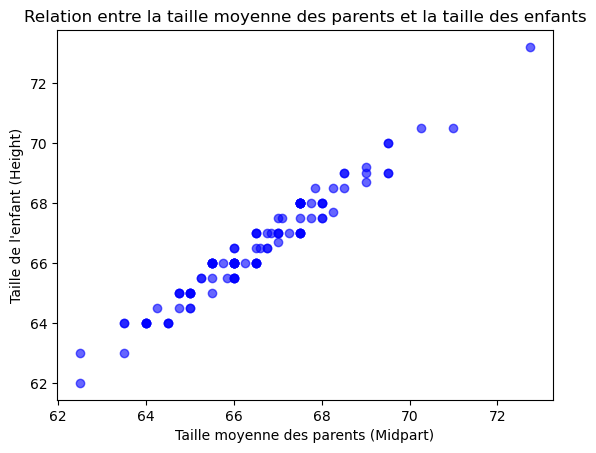

In [9]:
plt.scatter(data_clean["Midpart"], data_clean["Height"], color="blue", alpha=0.6)
plt.xlabel("Taille moyenne des parents (Midpart)")
plt.ylabel("Taille de l'enfant (Height)")
plt.title("Relation entre la taille moyenne des parents et la taille des enfants")
plt.show()

In [11]:
X = data_clean[["Midpart"]]   
y = data_clean["Height"]      

model = LinearRegression()
model.fit(X, y)

print("Coefficient (pente) :", model.coef_[0])
print("Intercept :", model.intercept_)

Coefficient (pente) : 1.008420857724604
Intercept : -0.537788624016045


In [14]:
prediction_data = pd.read_csv("prediction1.csv") 
model.predict(prediction_data[["Midpart"]])

array([69.54746099, 66.77430363, 69.7995662 , 69.7995662 , 69.04325056,
       69.04325056, 69.04325056, 68.53904013, 67.02640884, 67.02640884,
       68.28693492, 66.52219841, 68.28693492, 67.78272449, 67.78272449,
       67.02640884, 67.02640884, 67.27851406, 67.27851406, 67.27851406,
       67.02640884, 66.77430363, 66.77430363, 64.00114627, 68.79114534,
       67.53061927, 67.78272449, 67.02640884, 66.2700932 , 67.53061927,
       67.53061927, 67.53061927, 66.52219841, 66.77430363, 66.01798799,
       66.01798799, 65.86672486, 65.26167234, 63.49693584, 64.75746191,
       66.01798799, 65.76588277, 65.76588277, 64.00114627, 63.49693584,
       66.77430363])

### LA REGRESSION MULTIPLE

In [15]:
data2 = pd.read_csv("Data2.csv")
data2

,Father,Mother,Gender,Height
0,78.5,67.0,M,73.2
1,75.0,58.5,M,68.0
2,75.0,58.5,F,66.5
3,74.0,68.0,F,70.5
4,74.0,66.5,F,70.5
...,...,...,...,...
112,65.0,64.0,F,64.0
113,64.0,64.0,F,64.0
114,64.0,64.0,F,64.0
115,64.0,64.0,F,64.0


In [16]:
data2.describe()

,Father,Mother,Height
count,117.000000,117.000000,117.000000
mean,68.945299,64.093162,66.585470
std,2.714377,2.381890,1.875765
min,62.000000,58.500000,62.000000
25%,67.000000,63.000000,65.500000
50%,69.000000,64.000000,66.500000
75%,71.000000,66.000000,68.000000
max,78.500000,69.000000,73.200000


In [19]:
from sklearn.preprocessing import LabelEncoder

In [22]:
encoder = LabelEncoder() 
data2['Gender'] = encoder.fit_transform(data2['Gender'])
data2

,Father,Mother,Gender,Height
0,78.5,67.0,1,73.2
1,75.0,58.5,1,68.0
2,75.0,58.5,0,66.5
3,74.0,68.0,0,70.5
4,74.0,66.5,0,70.5
...,...,...,...,...
112,65.0,64.0,0,64.0
113,64.0,64.0,0,64.0
114,64.0,64.0,0,64.0
115,64.0,64.0,0,64.0


In [23]:
X = data2[['Father', 'Mother', 'Gender']] 
y = data2['Height'] 

model = LinearRegression() 
model.fit(X, y) 

print("Coefficient (pentes) :", model.coef_) 
print("Intercept :", model.intercept_)

Coefficient (pentes) : [0.51772854 0.49044001 0.27794463]
Intercept : -0.7001199626009225


In [27]:
prediction_data = pd.read_csv("prediction2.csv")
prediction_data['Gender'] = encoder.fit_transform(prediction_data['Gender'])
model.predict(prediction_data[['Father', 'Mother', 'Gender']])

array([69.79562632, 67.09820624, 69.98626927, 69.98626927, 69.25060925,
       69.25060925, 69.25060925, 68.73288071, 66.98361603, 66.98361603,
       68.46037217, 66.74383212, 68.15513902, 67.95628789, 67.95628789,
       67.20698361, 67.20698361, 67.46584788, 67.46584788, 67.46584788,
       67.20698361, 66.9617636 , 66.68381897, 63.98639889, 68.89623513,
       67.67013509, 67.63741047, 67.19333934, 66.44403506, 67.65649083,
       67.65649083, 67.65649083, 66.66196654, 66.92083081, 66.17152652,
       66.17152652, 66.02985222, 65.4358665 , 63.71932645, 64.65383759,
       65.83900484, 65.88537372, 65.87172946, 63.82266772, 63.61017234,
       66.92083081])